In [1]:
import pandas as pd

df = pd.read_csv('../data/car_fuel_efficiency_2026.csv')

In [2]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

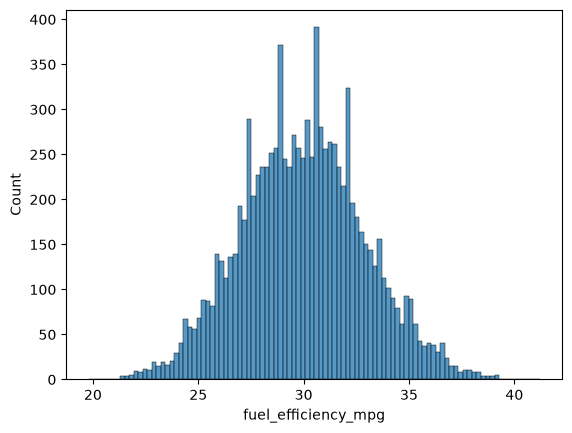

In [4]:
sns.histplot(df.fuel_efficiency_mpg, bins=100)

In [5]:
df.fuel_efficiency_mpg.describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

### Q1

In [6]:
features = [
    'engine_displacement',
    'horsepower',
    'vehicle_weight',
    'model_year',
    # 'fuel_efficiency_mpg',
]

df[features].isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
dtype: int64

In [7]:
# Q1: horsepower

### Q2

In [8]:
df['horsepower'].median()

np.float64(254.0)

In [9]:
# Q2: 254

### Q3

In [10]:
import numpy as np

In [11]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [12]:
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

In [13]:
print(df_train['horsepower'].mean())
print(df_val['horsepower'].mean())
print(df_test['horsepower'].mean())


254.46338337605272
254.38212719298247
254.4578116494284


In [14]:
def prepare_X(df, fill_val):
    df_num = df[features]
    df_num = df_num.fillna(fill_val)

    X = df_num.values

    return X

In [15]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [16]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()

    return np.sqrt(mse)

In [17]:
X_train = prepare_X(df_train, 0)
y_train = df_train['fuel_efficiency_mpg']
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, 0)
y_val = df_val['fuel_efficiency_mpg']

y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(2.20529319475341)

In [18]:
X_train = prepare_X(df_train, 254.46338337605272)
y_train = df_train['fuel_efficiency_mpg']
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val, 254.46338337605272)
y_val = df_val['fuel_efficiency_mpg']

y_pred = w0 + X_val.dot(w)

rmse(y_val, y_pred)

np.float64(2.2018174845688243)

In [19]:
print(f'RMSE with zeros: {round(2.20529319475341, 3)}')
print(f'RMSE with means: {round(2.2018174845688243, 3)}')

RMSE with zeros: 2.205
RMSE with means: 2.202


In [20]:
# Q3: with mean (RMSE is better)
# 2.205 / 2.202

### Q4

In [21]:
def train_linear_regression_regularized(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [22]:
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:

    X_train = prepare_X(df_train, 0)
    y_train = df_train['fuel_efficiency_mpg']
    w0, w = train_linear_regression_regularized(X_train, y_train, r)
    
    X_val = prepare_X(df_val, 0)
    y_val = df_val['fuel_efficiency_mpg']
    
    y_pred = w0 + X_val.dot(w)
    
    err = rmse(y_val, y_pred)

    print(f'{r}\t{w0}\t{round(err, 4)}')

0	-153.8849618823138	2.2053
0.01	-148.3092124404723	2.2058
0.1	-111.83871039306318	2.2241
1	-32.331865964971264	2.3492
5	-7.7728522099734025	2.4094
10	-3.9871164160193766	2.4195
100	-0.40821964884790385	2.4292


In [23]:
# Q4: r=0

### Q5

In [24]:
RMSEs = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:

    # Split dataset

    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test
    
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    # Train model

    X_train = prepare_X(df_train, 0)
    y_train = df_train['fuel_efficiency_mpg']
    w0, w = train_linear_regression(X_train, y_train)

    # Validate model
    
    X_val = prepare_X(df_val, 0)
    y_val = df_val['fuel_efficiency_mpg']
    
    y_pred = w0 + X_val.dot(w)
    
    err = rmse(y_val, y_pred)

    RMSEs.append(round(err, 3))


np.std(RMSEs)

np.float64(0.028915220905260306)

In [25]:
round(np.std(RMSEs), 3)

np.float64(0.029)

In [26]:
# Q5: 0.029

### Q6

In [34]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [35]:
df_full_train = pd.concat([df_train, df_val])

X_train = prepare_X(df_full_train, 0)
y_train = df_full_train['fuel_efficiency_mpg']

w0, w = train_linear_regression_regularized(X_train, y_train, 0.001)

X_test = prepare_X(df_test, 0)
y_test = df_test['fuel_efficiency_mpg']

y_pred = w0 + X_test.dot(w)

err = rmse(y_test, y_pred)
err

np.float64(2.235827747191731)

In [36]:
round(err, 3)

np.float64(2.236)

In [37]:
# Q6: 2.236